# ID2223 Lab Assignment 1 — Building and Evaluating CNNs on CIFAR-10

**AlexNet vs ResNet: capacity, regularization, robustness, adversarial examples and compute cost.**

This notebook follows the workflow from the Lab 1 notebook (`ID2223_Lab1.ipynb`): inspect the data, use a fixed seeded split, train with a `set_seed` / config dataclass setup, pick the checkpoint with the lowest validation cross-entropy, and open the test set only after all design decisions are frozen.

| Part | Content |
|---|---|
| 0 | Setup: device, run profile, artifact storage, reproducibility |
| Task 1 | Study and prepare CIFAR-10 |
| Task 2 | AlexNet and ResNet for CIFAR-10, baseline comparison, role of residual connections |
| Task 3 | Capacity (width/depth) and regularization (L2, dropout) |
| Task 4 | Data augmentation and robustness to corrupted images |
| Task 5 | Prediction analysis and adversarial examples |
| Task 6 | Benchmark and tradeoffs |
| Challenge 1 | Model compression (pruning, FP16, int8) |
| Challenge 2 | Generalization to unseen corruption families |

## How to reproduce

**Google Colab (full results used in the report).** Open the notebook in Colab, choose *Runtime → Change runtime type → T4 GPU*, and run all cells. The profile `full` is selected automatically on CUDA. Finished runs are stored in Google Drive (`MyDrive/kth-sml-lab1/full/`), so after a disconnect you can just *Run all* again: finished experiments are loaded instead of retrained.

**Local Mac (Apple Silicon).** From the project folder:
```bash
uv venv --python 3.12 .venv && source .venv/bin/activate
uv pip install torch torchvision numpy pandas matplotlib scikit-learn jupyter
jupyter lab   # open this notebook and run all cells
```
On MPS the profile `local` (shorter training budget) is selected. Set the environment variable `LAB_PROFILE=smoke` for a 2-minute end-to-end pipeline check, or `LAB_PROFILE=full` to force the full budget.

Each run writes `runs/<name>.json` (configuration, history, metrics, timing, hardware), `checkpoints/<name>.pt` and figures to `figures/` under the artifact directory.

## 0. Setup

In [1]:
import copy
import gzip
import io
import json
import math
import os
import platform
import random
import subprocess
import sys
import time
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from torch import nn
from torchvision.datasets import CIFAR10

try:
    from IPython.display import display
except ImportError:  # running as a plain script
    display = print

IN_COLAB = "google.colab" in sys.modules
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print("Python:", platform.python_version(), "| PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Running in Colab:", IN_COLAB)

Python: 3.12.13 | PyTorch: 2.15.0 | torchvision: 0.29.2
Running in Colab: False


**Device.** CUDA (Colab T4) is preferred, then Apple MPS, then CPU. Mixed precision (FP16 autocast) is only used on CUDA; MPS and CPU train in FP32. The device name is stored with every run because all timing results are hardware dependent.

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    DEVICE_NAME = torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    try:
        chip = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
    except Exception:
        chip = platform.machine()
    DEVICE_NAME = f"{chip} (MPS)"
else:
    device = torch.device("cpu")
    DEVICE_NAME = f"CPU ({platform.machine()})"

USE_AMP = device.type == "cuda"


def sync():
    """Wait for queued GPU work so wall-clock timings are honest."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP)


print("Device:", device, "|", DEVICE_NAME, "| AMP:", USE_AMP)

Device: mps | Apple M2 Pro (MPS) | AMP: False


**Run profile = compute budget.** Every model in one profile is trained with the *same* budget (epochs, batch size, schedule), which is what makes the comparisons fair.

| Profile | Used for | Training data | Epochs per run |
|---|---|---|---|
| `smoke` | pipeline check on any machine | 2,000 images | 2 |
| `local` | Apple M4 (MPS) | 45,000 images | 8 |
| `full` | Colab T4 — **results in the report** | 45,000 images | 15 |

In [3]:
PROFILES = {
    "smoke": dict(epochs=2, train_limit=2000, val_limit=1000, test_limit=1000, attack_n=64, pgd_steps=3, seed_repeats=1, finetune_epochs=1),
    "local": dict(epochs=8, train_limit=None, val_limit=None, test_limit=None, attack_n=500, pgd_steps=10, seed_repeats=1, finetune_epochs=1),
    "full": dict(epochs=15, train_limit=None, val_limit=None, test_limit=None, attack_n=1000, pgd_steps=10, seed_repeats=2, finetune_epochs=2),
}
PROFILE = os.environ.get("LAB_PROFILE") or {"cuda": "full", "mps": "local", "cpu": "smoke"}[device.type]
P = PROFILES[PROFILE]

FORCE_RETRAIN = False     # True = ignore stored runs and train everything again
RUN_CHALLENGES = True     # optional extensions at the end
USE_DRIVE = True          # Colab only: keep artifacts in Google Drive across sessions

print("Profile:", PROFILE, P)

Profile: local {'epochs': 8, 'train_limit': None, 'val_limit': None, 'test_limit': None, 'attack_n': 500, 'pgd_steps': 10, 'seed_repeats': 1, 'finetune_epochs': 1}


**Artifact storage.** On Colab, results go to Google Drive so they survive a disconnected runtime; locally they go to `artifacts/<profile>/` next to the notebook. Small JSON results and figures can be committed to Git; checkpoints (`*.pt`) are git-ignored.

In [4]:
if IN_COLAB and USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    ARTIFACT_ROOT = Path("/content/drive/MyDrive/kth-sml-lab1")
else:
    ARTIFACT_ROOT = Path("artifacts")
DATA_DIR = Path("/content/data") if IN_COLAB else Path("data")

ART = ARTIFACT_ROOT / PROFILE
RUN_DIR, CKPT_DIR, FIG_DIR, CACHE_DIR = (ART / d for d in ("runs", "checkpoints", "figures", "cache"))
for d in (RUN_DIR, CKPT_DIR, FIG_DIR, CACHE_DIR, DATA_DIR):
    d.mkdir(parents=True, exist_ok=True)


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Artifacts:", ART.resolve())
print("Data:", DATA_DIR.resolve())

Artifacts: /Users/Pheleebay/Documents/kth-sml-lab-assign/artifacts/local
Data: /Users/Pheleebay/Documents/kth-sml-lab-assign/data


**Randomness control.** Separate seeds are used for each source of randomness, so that changing one experiment does not silently change another:

* `SPLIT_SEED` — the train/validation partition (same value as in Lab 1),
* `BASE_SEED` — weight initialization, mini-batch order, dropout masks and augmentation (one `torch.Generator` per run),
* `CORRUPTION_SEED` — the fixed corrupted evaluation sets,
* `ATTACK_SEED` — the random start of the PGD attack.

cuDNN autotuning is disabled and deterministic algorithms are requested. Bit-exact reproducibility is still only guaranteed on the same hardware and software versions: some GPU kernels (and MPS in general) are not deterministic, which is why Task 6 also repeats the baselines with different seeds.

In [5]:
SPLIT_SEED = 2223
BASE_SEED = 42
CORRUPTION_SEED = 7
ATTACK_SEED = 123

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if device.type == "mps":
        torch.mps.manual_seed(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


set_seed(BASE_SEED)

# Task 1. Study and prepare the data

### 1.1 Load CIFAR-10
CIFAR-10 ([Krizhevsky, 2009](https://www.cs.toronto.edu/~kriz/cifar.html)) is loaded with `torchvision.datasets.CIFAR10`, which downloads the official archive and verifies its MD5 checksum. We keep the raw `uint8` pixels and convert them to `[N, 3, 32, 32]` tensors (channels first, as PyTorch convolutions expect).

In [6]:
train_source = CIFAR10(DATA_DIR, train=True, download=True)
test_source = CIFAR10(DATA_DIR, train=False, download=True)
CLASSES = train_source.classes
NUM_CLASSES = len(CLASSES)

X_trainval = torch.from_numpy(train_source.data).permute(0, 3, 1, 2).contiguous()  # uint8 [50000, 3, 32, 32]
y_trainval = torch.tensor(train_source.targets, dtype=torch.long)
X_test_all = torch.from_numpy(test_source.data).permute(0, 3, 1, 2).contiguous()   # uint8 [10000, 3, 32, 32]
y_test_all = torch.tensor(test_source.targets, dtype=torch.long)

print("Provided training images:", tuple(X_trainval.shape), X_trainval.dtype)
print("Provided test images:    ", tuple(X_test_all.shape), X_test_all.dtype)
print("Pixel range:", int(X_trainval.min()), "to", int(X_trainval.max()))
print("Classes:", CLASSES)

assert X_trainval.shape == (50000, 3, 32, 32) and X_test_all.shape == (10000, 3, 32, 32)
assert set(y_trainval.unique().tolist()) == set(range(10))

Provided training images: (50000, 3, 32, 32) torch.uint8
Provided test images:     (10000, 3, 32, 32) torch.uint8
Pixel range: 0 to 255
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### 1.2 What does an example represent, and how are the classes distributed?
An example is a 32×32 RGB photograph (3,072 values in 0–255) of a single object, labelled with one of ten mutually exclusive classes: six animals and four vehicles. Objects are roughly centred, but vary in pose, scale, background and lighting. The resolution is very low, so fine details (for example, what separates a cat from a dog) are often only a few pixels.

In [7]:
class_counts = pd.DataFrame(
    {
        "provided train": np.bincount(y_trainval.numpy(), minlength=10),
        "provided test": np.bincount(y_test_all.numpy(), minlength=10),
    },
    index=CLASSES,
)
display(class_counts)

,provided train,provided test
airplane,5000,1000
automobile,5000,1000
bird,5000,1000
cat,5000,1000
deer,5000,1000
dog,5000,1000
frog,5000,1000
horse,5000,1000
ship,5000,1000
truck,5000,1000


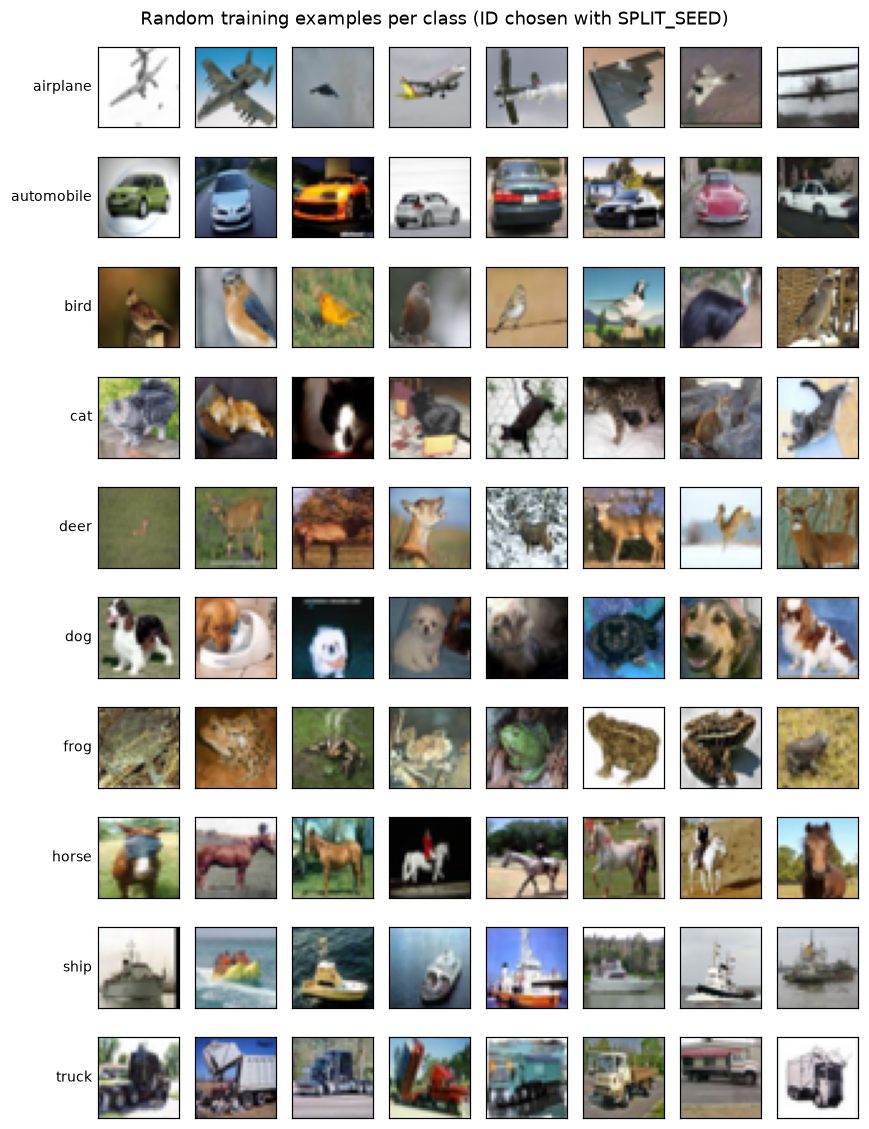

In [8]:
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(8, 10.5))
rng = np.random.default_rng(SPLIT_SEED)
for c in range(NUM_CLASSES):
    picks = rng.choice(np.flatnonzero(y_trainval.numpy() == c), size=8, replace=False)
    for j, idx in enumerate(picks):
        ax = axes[c, j]
        ax.imshow(X_trainval[idx].permute(1, 2, 0).numpy())
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if j == 0:
            ax.set_ylabel(CLASSES[c], rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Random training examples per class (ID chosen with SPLIT_SEED)")
fig.tight_layout()
savefig(fig, "t1_examples")
plt.show()

**Image statistics.** Per-channel brightness and contrast differ between classes (for example, ships and airplanes often have blue/bright backgrounds). A classifier can exploit such shortcuts, which matters later when we change colours or add noise.

In [9]:
x01 = X_trainval.float() / 255.0
per_image = pd.DataFrame(
    {
        "class": [CLASSES[i] for i in y_trainval.tolist()],
        "brightness": x01.mean(dim=(1, 2, 3)).numpy(),
        "contrast (pixel std)": x01.std(dim=(1, 2, 3)).numpy(),
        "R": x01[:, 0].mean(dim=(1, 2)).numpy(),
        "G": x01[:, 1].mean(dim=(1, 2)).numpy(),
        "B": x01[:, 2].mean(dim=(1, 2)).numpy(),
    }
)
display(per_image.groupby("class").mean().round(3))
del x01

,brightness,contrast (pixel std),R,G,B
class,,,,,
airplane,0.558,0.204,0.526,0.560,0.589
automobile,0.458,0.237,0.471,0.455,0.447
bird,0.468,0.182,0.489,0.491,0.424
cat,0.456,0.217,0.495,0.456,0.416
deer,0.438,0.179,0.472,0.465,0.378
dog,0.460,0.217,0.500,0.465,0.417
frog,0.418,0.187,0.470,0.438,0.345
horse,0.466,0.221,0.502,0.480,0.417
ship,0.523,0.216,0.490,0.525,0.555


### 1.3 How is the dataset split?
Following Lab 1, the provided **50,000 training images** are split with a stratified, seeded split into **45,000 training** and **5,000 validation** images (500 per class). The **10,000 test images** are kept for the final evaluation only; they are not used for checkpoint selection, hyperparameter choice or model selection. Original sample IDs are kept, so every prediction can be traced back to its image.

In [10]:
all_ids = np.arange(len(y_trainval))
train_ids, val_ids = train_test_split(
    all_ids, test_size=5000, stratify=y_trainval.numpy(), random_state=SPLIT_SEED
)
test_ids = np.arange(len(y_test_all))


def stratified_limit(ids, labels, limit):
    """Smaller stratified subset for the smoke profile (no-op when limit is None)."""
    if limit is None or limit >= len(ids):
        return ids
    keep, _ = train_test_split(ids, train_size=limit, stratify=labels[ids], random_state=SPLIT_SEED)
    return keep


train_ids = np.sort(stratified_limit(train_ids, y_trainval.numpy(), P["train_limit"]))
val_ids = np.sort(stratified_limit(val_ids, y_trainval.numpy(), P["val_limit"]))
test_ids = np.sort(stratified_limit(test_ids, y_test_all.numpy(), P["test_limit"]))

# A fixed subset of the training split, evaluated without augmentation or dropout, gives a
# deterministic training accuracy of the selected checkpoint (the running accuracy logged during an
# epoch is measured with augmentation/dropout switched on and with changing weights).
train_eval_ids = np.sort(np.random.default_rng(SPLIT_SEED).choice(train_ids, size=min(5000, len(train_ids)), replace=False))

assert not set(train_ids) & set(val_ids)
split_counts = pd.DataFrame(
    {
        "train": np.bincount(y_trainval.numpy()[train_ids], minlength=10),
        "validation": np.bincount(y_trainval.numpy()[val_ids], minlength=10),
        "test": np.bincount(y_test_all.numpy()[test_ids], minlength=10),
    },
    index=CLASSES,
)
split_counts.loc["total"] = split_counts.sum()
display(split_counts)

,train,validation,test
airplane,4500,500,1000
automobile,4500,500,1000
bird,4500,500,1000
cat,4500,500,1000
deer,4500,500,1000
dog,4500,500,1000
frog,4500,500,1000
horse,4500,500,1000
ship,4500,500,1000
truck,4500,500,1000


### 1.4 Which preprocessing is needed for the two architectures?
* **Scale to [0, 1].** A fixed conversion (divide by 255) with no learned statistics.
* **Per-channel standardization** $z = (x - \mu_c)/\sigma_c$, where $\mu_c, \sigma_c$ are computed **on the training split only** (as with the `StandardScaler` in Lab 1). This centres the inputs of the first convolution and makes one learning rate suitable for all channels.
* **No resizing.** The original AlexNet expects 227×227 inputs and ResNet expects 224×224. Upsampling 32×32 images by 7× adds no information and costs about 50× more compute, so instead both architectures are *adapted* to 32×32 inputs (Task 2). Both models therefore receive exactly the same input tensor.
* **Normalization inside the model.** Standardization is implemented as the first layer (`Normalize`) of every model, with $\mu, \sigma$ stored as buffers in the checkpoint. The models therefore take raw `[0, 1]` images. This makes saved checkpoints self-contained (the "preprocessing contract" from Lab 1 A6), and lets corruptions and adversarial perturbations be defined in pixel space with valid pixel bounds.
* **Data augmentation** is a training-time choice, studied separately in Task 4. Baselines in Tasks 2 and 3 are trained **without augmentation**, so that overfitting is visible.

In [11]:
def channel_stats(images_uint8, chunk=5000):
    total = torch.zeros(3, dtype=torch.float64)
    total_sq = torch.zeros(3, dtype=torch.float64)
    n = 0
    for start in range(0, len(images_uint8), chunk):
        x = images_uint8[start:start + chunk].to(torch.float64) / 255.0
        total += x.sum(dim=(0, 2, 3))
        total_sq += (x ** 2).sum(dim=(0, 2, 3))
        n += x.shape[0] * x.shape[2] * x.shape[3]
    mean = total / n
    std = (total_sq / n - mean ** 2).sqrt()
    return mean.float(), std.float()


CIFAR_MEAN, CIFAR_STD = channel_stats(X_trainval[train_ids])
print("Training-split mean (R, G, B):", CIFAR_MEAN.numpy().round(4))
print("Training-split std  (R, G, B):", CIFAR_STD.numpy().round(4))

Training-split mean (R, G, B): [0.4913 0.4822 0.4464]
Training-split std  (R, G, B): [0.247  0.2434 0.2615]


### 1.5 Reusable, device-resident data pipeline
CIFAR-10 is small (150 MB as `uint8`), so each split is moved to the accelerator **once**, and batches are produced by indexing on the device. This avoids the CPU `DataLoader` bottleneck on Colab (only 2 CPU cores), and keeps augmentation on the GPU. Shuffling uses a seeded `torch.Generator`, as in Lab 1.

In [12]:
class TensorData:
    """A split held on the device: uint8 images, labels and the original sample IDs."""

    def __init__(self, images_uint8, labels, ids, name):
        self.x = images_uint8.to(device)
        self.y = labels.to(device)
        self.ids = torch.as_tensor(np.asarray(ids))
        self.name = name

    def __len__(self):
        return len(self.ids)


def iterate(data, batch_size, generator=None):
    """Yield (uint8 images, labels, ids). Shuffled when a generator is given."""
    n = len(data)
    order = torch.randperm(n, generator=generator) if generator is not None else torch.arange(n)
    for start in range(0, n, batch_size):
        idx = order[start:start + batch_size]
        idx_dev = idx.to(device)
        yield data.x[idx_dev], data.y[idx_dev], data.ids[idx]


def to_float(x_uint8):
    return x_uint8.float().div_(255.0)


SPLITS = {
    "train": TensorData(X_trainval[train_ids], y_trainval[train_ids], train_ids, "train"),
    "train_eval": TensorData(X_trainval[train_eval_ids], y_trainval[train_eval_ids], train_eval_ids, "train_eval"),
    "val": TensorData(X_trainval[val_ids], y_trainval[val_ids], val_ids, "val"),
    "test": TensorData(X_test_all[test_ids], y_test_all[test_ids], test_ids, "test"),
}
for k, v in SPLITS.items():
    print(f"{k:>10}: {len(v):>6} images on {v.x.device}")

     train:  45000 images on mps:0
train_eval:   5000 images on mps:0
       val:   5000 images on mps:0
      test:  10000 images on mps:0


### 1.6 Training-time data augmentation (used in Task 4)
Three augmentation conditions are implemented on the GPU with the run's seeded generator:

| Condition | Transformations |
|---|---|
| `none` | none (original images) |
| `standard` | random crop (4-pixel reflection padding) + random horizontal flip |
| `strong` | `standard` + with p = 0.5 a random rotation (±15°) and shear (±10°), + with p = 0.5 Gaussian noise (σ ~ U(0, 0.06)) |

Horizontal flips and small translations keep the label for every CIFAR-10 class. A vertical flip would not (an upside-down ship or horse is not a natural image), so it is not used.

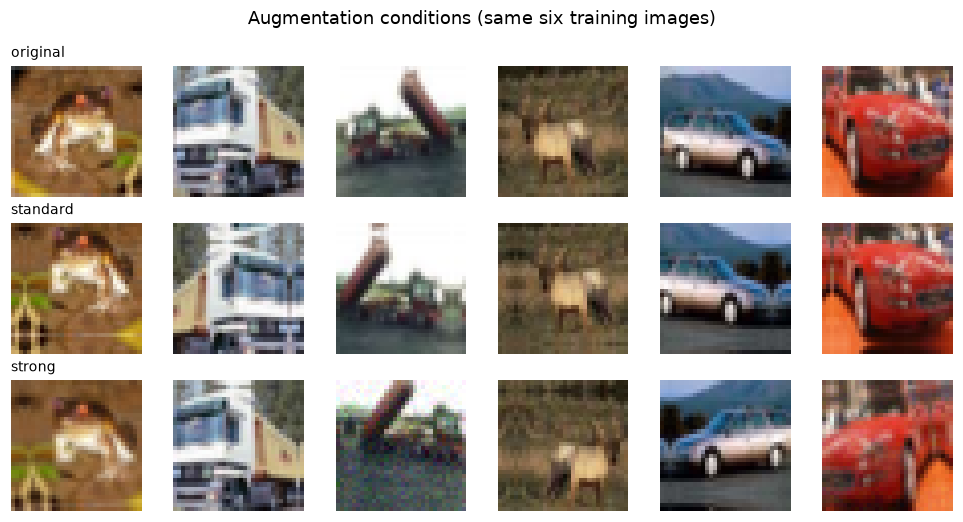

In [13]:
def affine_batch(x, angle_deg, shear_deg=None, scale=None, padding_mode="reflection"):
    """Rotate / shear / scale each image of a [B, 3, H, W] batch around its centre (bilinear)."""
    B = x.shape[0]
    angle = torch.deg2rad(angle_deg.float())
    shear = torch.deg2rad(shear_deg.float()) if shear_deg is not None else torch.zeros(B)
    scale = scale.float() if scale is not None else torch.ones(B)
    cos, sin = torch.cos(angle), torch.sin(angle)
    rot = torch.stack([torch.stack([cos, -sin], -1), torch.stack([sin, cos], -1)], -2)          # [B, 2, 2]
    shr = torch.stack([torch.stack([torch.ones(B), torch.tan(shear)], -1),
                       torch.stack([torch.zeros(B), torch.ones(B)], -1)], -2)
    A = (rot @ shr) / scale[:, None, None]       # maps output coordinates to input coordinates
    theta = torch.cat([A, torch.zeros(B, 2, 1)], dim=2).to(x.device, x.dtype)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode=padding_mode, align_corners=False)


def random_crop_flip(x, gen, pad=4):
    B, C, H, W = x.shape
    padded = F.pad(x, (pad, pad, pad, pad), mode="reflect")
    dy = torch.randint(0, 2 * pad + 1, (B,), generator=gen).to(x.device)
    dx = torch.randint(0, 2 * pad + 1, (B,), generator=gen).to(x.device)
    rows = dy[:, None] + torch.arange(H, device=x.device)[None, :]
    cols = dx[:, None] + torch.arange(W, device=x.device)[None, :]
    out = padded[
        torch.arange(B, device=x.device)[:, None, None, None],
        torch.arange(C, device=x.device)[None, :, None, None],
        rows[:, None, :, None],
        cols[:, None, None, :],
    ]
    flip = (torch.rand(B, generator=gen) < 0.5).to(x.device)
    return torch.where(flip[:, None, None, None], out.flip(3), out)


def augment(x, kind, gen):
    """x: float batch in [0, 1] on the device. gen: CPU generator owned by the run."""
    if kind == "none":
        return x
    x = random_crop_flip(x, gen)
    if kind == "strong":
        B = x.shape[0]
        apply = (torch.rand(B, generator=gen) < 0.5).float()
        angle = (torch.rand(B, generator=gen) * 2 - 1) * 15 * apply
        shear = (torch.rand(B, generator=gen) * 2 - 1) * 10 * apply
        x = affine_batch(x, angle, shear)
        sigma = torch.rand(B, generator=gen) * 0.06 * (torch.rand(B, generator=gen) < 0.5).float()
        noise = torch.randn(x.shape, generator=gen) * sigma[:, None, None, None]
        x = (x + noise.to(x.device)).clamp_(0, 1)
    elif kind != "standard":
        raise ValueError(kind)
    return x


demo_gen = torch.Generator().manual_seed(0)
demo = to_float(SPLITS["train"].x[:6])
rows = {"original": demo, "standard": augment(demo, "standard", demo_gen), "strong": augment(demo, "strong", demo_gen)}
fig, axes = plt.subplots(3, 6, figsize=(9, 4.8))
for r, (title, batch) in enumerate(rows.items()):
    for j in range(6):
        axes[r, j].imshow(batch[j].permute(1, 2, 0).cpu().numpy())
        axes[r, j].axis("off")
    axes[r, 0].set_title(title, loc="left", fontsize=9)
fig.suptitle("Augmentation conditions (same six training images)")
fig.tight_layout()
savefig(fig, "t1_augmentations")
plt.show()

# Task 2. Implement and compare AlexNet and ResNet

Both architectures were designed for ImageNet (224×224 inputs, 1,000 classes). Applied unchanged to 32×32 CIFAR-10 images, their aggressive early downsampling (AlexNet: 11×11 convolution with stride 4 followed by max-pooling; ResNet: 7×7 convolution with stride 2 followed by max-pooling) would shrink a 32×32 image to a 2×2 or 1×1 feature map before most of the network has seen it. We therefore use the standard CIFAR adaptations: **keep the overall structure (layer types, ordering, channel progression and head), but remove the early downsampling** so that the spatial resolution is reduced gradually.

### 2.1 Shared building blocks
`Normalize` is the first layer of every model (see 1.4): it applies the training-split channel statistics, so a model takes raw `[0, 1]` images. Two helpers count parameters and multiply–accumulate operations (MACs) of one forward pass; MACs are counted for convolutions and linear layers (which dominate the cost) by forward hooks.

In [14]:
class Normalize(nn.Module):
    # Per-channel standardization stored as buffers, so it is saved with every checkpoint.
    def __init__(self, mean=CIFAR_MEAN, std=CIFAR_STD):
        super().__init__()
        self.register_buffer("mean", mean.clone().view(1, 3, 1, 1))
        self.register_buffer("std", std.clone().view(1, 3, 1, 1))

    def forward(self, x):
        return (x - self.mean) / self.std


def count_params(model):
    return sum(p.numel() for p in model.parameters())


@torch.no_grad()
def count_macs(model, input_shape=(1, 3, 32, 32)):
    # Multiply-accumulate operations of conv and linear layers for one image.
    total = 0

    def hook(module, inputs, output):
        nonlocal total
        if isinstance(module, nn.Conv2d):
            k = module.kernel_size[0] * module.kernel_size[1] * module.in_channels // module.groups
            total += output[0].numel() * k
        elif isinstance(module, nn.Linear):
            total += module.in_features * module.out_features

    handles = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    was_training = model.training
    model.eval()
    p = next(model.parameters())
    model(torch.zeros(input_shape, device=p.device, dtype=p.dtype))
    model.train(was_training)
    for h in handles:
        h.remove()
    return total


@torch.no_grad()
def layer_table(model, layers):
    # Output shape and parameter count of the named sub-modules, in forward order.
    rows, handles = [], []
    for name, module in layers:
        def hook(m, inp, out, name=name):
            rows.append({"layer": name, "type": type(m).__name__,
                         "output shape (C×H×W)": "×".join(map(str, out.shape[1:])),
                         "parameters": sum(p.numel() for p in m.parameters())})
        handles.append(module.register_forward_hook(hook))
    was_training = model.training
    model.eval()
    p = next(model.parameters())
    model(torch.zeros(1, 3, 32, 32, device=p.device))
    model.train(was_training)
    for h in handles:
        h.remove()
    table = pd.DataFrame(rows)
    table.loc[len(table)] = {"layer": "total", "type": "", "output shape (C×H×W)": "", "parameters": count_params(model)}
    return table

### 2.2 AlexNet for CIFAR-10

| | Original AlexNet (Krizhevsky et al., 2012) | AlexNet-CIFAR (ours) | Why |
|---|---|---|---|
| Input | 227×227×3 | 32×32×3 | native CIFAR resolution, no upsampling (1.4) |
| conv1 | 96 filters, 11×11, stride 4 | 64 filters, **5×5, stride 1** | an 11×11/4 filter would cover a third of the image and leave a 7×7 map |
| conv2 | 256, 5×5 | 192, 5×5 | |
| conv3–5 | 384, 384, 256, 3×3 | 384, 256, 256, 3×3 | channel widths of the common torchvision single-GPU variant |
| Pooling | 3×3 overlapping max-pool, stride 2, after conv1, conv2, conv5 | same (padding 1), 32 → 16 → 8 → 4 | kept; three halvings give a 4×4 final map |
| Normalization | Local response normalization (LRN) | **BatchNorm** after each convolution | LRN is no longer used; BN gives stable training at one learning rate shared with ResNet |
| Two-GPU split | grouped convolutions across 2 GPUs | none | an implementation detail of 2012 hardware |
| Head | dropout → FC 4096 → dropout → FC 4096 → FC 1000 | dropout → **FC 1024** → dropout → **FC 1024** → FC 10 | the flattened input is 4,096 values instead of 9,216, so 4096-wide FC layers would mostly add parameters (≈ 25 M) |
| Dropout | p = 0.5 | p = 0.5 (studied in Task 3) | |

A `width` multiplier scales all convolution channels; `width = 1` is the baseline.

In [15]:
def conv_bn_relu(c_in, c_out, kernel):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel, padding=kernel // 2, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
    )


class AlexNetCIFAR(nn.Module):
    def __init__(self, width=1.0, dropout=0.5, hidden=1024, num_classes=NUM_CLASSES):
        super().__init__()
        c1, c2, c3, c4, c5 = (max(8, int(round(c * width))) for c in (64, 192, 384, 256, 256))
        self.normalize = Normalize()
        self.features = nn.Sequential(
            conv_bn_relu(3, c1, 5), nn.MaxPool2d(3, stride=2, padding=1),    # 32 -> 16
            conv_bn_relu(c1, c2, 5), nn.MaxPool2d(3, stride=2, padding=1),   # 16 -> 8
            conv_bn_relu(c2, c3, 3),
            conv_bn_relu(c3, c4, 3),
            conv_bn_relu(c4, c5, 3), nn.MaxPool2d(3, stride=2, padding=1),   # 8 -> 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(c5 * 4 * 4, hidden), nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.ReLU(inplace=True),
            nn.Linear(hidden, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(self.normalize(x)))

    def named_layers(self):
        names = ["conv1", "pool1", "conv2", "pool2", "conv3", "conv4", "conv5", "pool5"]
        head = ["flatten", "dropout1", "fc6", "relu6", "dropout2", "fc7", "relu7", "fc8 (logits)"]
        return list(zip(names, self.features)) + list(zip(head, self.classifier))


alexnet_demo = AlexNetCIFAR()
display(layer_table(alexnet_demo, alexnet_demo.named_layers()))
print(f"AlexNet-CIFAR: {count_params(alexnet_demo) / 1e6:.2f} M parameters, {count_macs(alexnet_demo) / 1e6:.0f} M MACs per image")

,layer,type,output shape (C×H×W),parameters
0,conv1,Sequential,64×32×32,4928
1,pool1,MaxPool2d,64×16×16,0
2,conv2,Sequential,192×16×16,307584
3,pool2,MaxPool2d,192×8×8,0
4,conv3,Sequential,384×8×8,664320
5,conv4,Sequential,256×8×8,885248
6,conv5,Sequential,256×8×8,590336
7,pool5,MaxPool2d,256×4×4,0
8,flatten,Flatten,4096,0
9,dropout1,Dropout,4096,0


AlexNet-CIFAR: 7.71 M parameters, 226 M MACs per image


### 2.3 ResNet-18 for CIFAR-10

| | Original ResNet-18 (He et al., 2016) | ResNet-18-CIFAR (ours) | Why |
|---|---|---|---|
| Stem | 7×7 conv, 64, stride 2 + 3×3 max-pool stride 2 (224 → 56) | **3×3 conv, 64, stride 1, no max-pool** (32 → 32) | the ImageNet stem would leave an 8×8 map before the first residual stage |
| Stages | 4 stages × 2 BasicBlocks, 64/128/256/512 channels, stride 1/2/2/2 | unchanged | |
| Feature maps | 56 → 28 → 14 → 7 | 32 → 16 → 8 → 4 | |
| Shortcut when the shape changes | 1×1 convolution with stride 2 + BN ("option B") | unchanged | |
| Head | global average pool → FC 1000 | global average pool → FC 10 | |

This is the widely used CIFAR variant of ResNet-18 (e.g. the `kuangliu/pytorch-cifar` reference implementation). It is different from the much smaller "ResNet-20" of He et al. §4.2 (16/32/64 channels, 0.27 M parameters). We use the ImageNet channel widths so that the two baselines have a similar parameter budget (≈ 11 M); Task 3 then varies width and depth.

Two experimental switches are added, both **off** in the baseline:
* `residual=False` removes every shortcut (including the 1×1 projections) — a *plain* network with exactly the same convolution stack (used in 2.6),
* `width` and `blocks` change capacity (Task 3).

**Basic block.** `out = ReLU(BN(conv3×3(ReLU(BN(conv3×3(x))))) + shortcut(x))`.

In [16]:
class BasicBlock(nn.Module):
    def __init__(self, c_in, c_out, stride, residual=True):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.residual = residual
        self.shortcut = nn.Identity()
        if residual and (stride != 1 or c_in != c_out):
            self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False), nn.BatchNorm2d(c_out))

    def forward(self, x):
        out = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, blocks=(2, 2, 2, 2), width=1.0, residual=True, dropout=0.0, num_classes=NUM_CLASSES):
        super().__init__()
        widths = [max(8, int(round(c * width))) for c in (64, 128, 256, 512)]
        self.normalize = Normalize()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        stages, c_in = [], widths[0]
        for i, (n, c) in enumerate(zip(blocks, widths)):
            layers = []
            for j in range(n):
                layers.append(BasicBlock(c_in, c, stride=2 if (i > 0 and j == 0) else 1, residual=residual))
                c_in = c
            stages.append(nn.Sequential(*layers))
        self.stages = nn.Sequential(*stages)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(c_in, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        x = self.stages(self.stem(self.normalize(x)))
        return self.fc(self.dropout(torch.flatten(self.pool(x), 1)))

    def named_layers(self):
        layers = [("stem conv3×3", self.stem)]
        for i, stage in enumerate(self.stages):
            for j, block in enumerate(stage):
                layers.append((f"stage{i + 1}.block{j + 1}", block))
        return layers + [("global avg pool", self.pool), ("fc (logits)", self.fc)]


resnet_demo = ResNetCIFAR()
display(layer_table(resnet_demo, resnet_demo.named_layers()))
print(f"ResNet-18-CIFAR: {count_params(resnet_demo) / 1e6:.2f} M parameters, {count_macs(resnet_demo) / 1e6:.0f} M MACs per image")

,layer,type,output shape (C×H×W),parameters
0,stem conv3×3,Sequential,64×32×32,1856
1,stage1.block1,BasicBlock,64×32×32,73984
2,stage1.block2,BasicBlock,64×32×32,73984
3,stage2.block1,BasicBlock,128×16×16,230144
4,stage2.block2,BasicBlock,128×16×16,295424
5,stage3.block1,BasicBlock,256×8×8,919040
6,stage3.block2,BasicBlock,256×8×8,1180672
7,stage4.block1,BasicBlock,512×4×4,3673088
8,stage4.block2,BasicBlock,512×4×4,4720640
9,global avg pool,AdaptiveAvgPool2d,512×1×1,0


ResNet-18-CIFAR: 11.17 M parameters, 555 M MACs per image


### 2.4 What the convolutions do
* **Local, weight-shared filters.** Each output value of a convolution depends only on a small neighbourhood (3×3 or 5×5) of the previous map, and the same filter is applied at every position. This builds in two properties of natural images: nearby pixels are related, and an edge or texture means the same thing wherever it appears (translation equivariance). It is also why a conv layer has far fewer parameters than a fully connected layer on the same input: AlexNet's conv2 maps a 64×16×16 tensor to 192×16×16 with 0.3 M weights; a dense layer between the same tensors would need 3.2 billion.
* **A hierarchy of features.** The first layer acts on raw pixels and learns colour blobs and oriented edges; each later layer combines the previous maps over a larger *receptive field*. After conv1–conv5 of AlexNet-CIFAR (with three poolings) and after the 17 convolutions of ResNet-18, a unit sees the whole 32×32 image, so late layers can respond to object parts and whole objects.
* **Downsampling.** Max-pooling (AlexNet) and stride-2 convolutions (ResNet) halve the resolution while the number of channels grows, trading *where* for *what*. Max-pooling also gives a small amount of invariance to shifts of a few pixels.
* **1×1 convolutions** in the ResNet projection shortcuts only mix channels (no spatial context); they match the shape of the shortcut to the residual branch.
* **BatchNorm + ReLU.** BN normalizes each channel over the mini-batch (and uses running statistics at test time, which is why `model.eval()` matters); ReLU provides the non-linearity.
* **Head.** AlexNet flattens the 256×4×4 map and uses two large FC layers — they hold 4.2 M of its parameters and are where dropout acts. ResNet averages each of the 512 maps to one value (global average pooling) and uses a single linear layer, so the head is tiny (5 k parameters) and the representation is less tied to exact positions.

### 2.5 Training procedure and compute budget
One configuration dataclass describes a run (as in Lab 1) and is stored with its results. Both baselines use **the same procedure and budget**:

| Setting | Value | Reason |
|---|---|---|
| Training data | 45,000 images of the training split, **no augmentation** (Task 4 adds it) | overfitting and regularization effects stay visible |
| Optimizer | SGD, momentum 0.9 (Nesterov), batch size 128 | the standard choice for both architectures on CIFAR |
| Learning rate | peak 0.05, linear warm-up over the first epoch, cosine decay to 0 at the last step | a schedule that ends at a low LR gives a well-converged model within a fixed number of epochs |
| L2 regularization | weight decay 5·10⁻⁴ on conv/linear weights (not on BN and biases) | common CIFAR value; varied in Task 3 |
| Dropout | AlexNet 0.5 in the FC head (as the original); ResNet none (as the original) | varied in Task 3 |
| Epochs | `P["epochs"]` of the profile: 8 (`local`, Apple M4) or 15 (`full`, Colab T4) | the compute budget; identical for every run of a profile |
| Seed | `BASE_SEED` for initialization, batch order and dropout | |
| Precision | FP16 autocast on CUDA, FP32 on MPS/CPU | |

**Checkpoint selection.** After every epoch the model is evaluated on the validation split, and the weights with the **lowest validation cross-entropy** are kept (Lab 1). Cross-entropy is preferred over accuracy because it also reacts to over-confident wrong predictions, which is the first sign of overfitting. The test split is not used here.

**What is logged.** Per epoch: running training loss/accuracy (measured with dropout on and changing weights), validation loss/accuracy, and wall-clock time. For the selected checkpoint: a deterministic evaluation of `train_eval` (5,000 fixed training images, eval mode) and of the validation split, so that the train–validation gap is measured on equal terms.

**Caching.** Each run is saved as `runs/<name>.json` + `checkpoints/<name>.pt`. If a run with the identical configuration exists it is loaded instead of retrained (`FORCE_RETRAIN = True` overrides this).

In [17]:
@dataclass(frozen=True)
class RunConfig:
    name: str
    arch: str                      # "alexnet" | "resnet"
    width: float = 1.0             # channel multiplier (1.0 = baseline)
    blocks: tuple = (2, 2, 2, 2)   # ResNet BasicBlocks per stage
    residual: bool = True          # ResNet only: False removes every shortcut
    dropout: float = 0.0
    weight_decay: float = 5e-4
    lr: float = 0.05
    momentum: float = 0.9
    batch_size: int = 128
    epochs: int = P["epochs"]
    warmup_epochs: int = 1
    augment: str = "none"
    seed: int = BASE_SEED


def build_model(cfg):
    if cfg.arch == "alexnet":
        return AlexNetCIFAR(width=cfg.width, dropout=cfg.dropout)
    if cfg.arch == "resnet":
        return ResNetCIFAR(blocks=cfg.blocks, width=cfg.width, residual=cfg.residual, dropout=cfg.dropout)
    raise ValueError(cfg.arch)


def config_dict(cfg):
    d = asdict(cfg)
    d["blocks"] = list(d["blocks"])
    return d


@torch.inference_mode()
def evaluate(model, data, batch_size=1000, transform=None):
    # Eval-mode metrics on a TensorData split; keeps ids for later error analysis.
    model.eval()
    loss_sum, logits_all = 0.0, []
    for xb, yb, _ in iterate(data, batch_size):
        x = to_float(xb)
        if transform is not None:
            x = transform(x)
        with autocast():
            logits = model(x)
        logits = logits.float()
        loss_sum += F.cross_entropy(logits, yb, reduction="sum").item()
        logits_all.append(logits.cpu())
    logits = torch.cat(logits_all)
    targets = data.y.cpu().numpy()
    preds = logits.argmax(1).numpy()
    return {
        "cross_entropy": loss_sum / len(data),
        "accuracy": accuracy_score(targets, preds),
        "macro_f1": f1_score(targets, preds, average="macro"),
        "ids": data.ids.numpy(), "targets": targets, "predictions": preds,
        "probabilities": logits.softmax(1).numpy(),
    }


def make_optimizer(model, cfg):
    decay = [p for n, p in model.named_parameters() if p.ndim > 1]          # conv / linear weights
    no_decay = [p for n, p in model.named_parameters() if p.ndim <= 1]      # BN parameters and biases
    return torch.optim.SGD(
        [{"params": decay, "weight_decay": cfg.weight_decay}, {"params": no_decay, "weight_decay": 0.0}],
        lr=cfg.lr, momentum=cfg.momentum, nesterov=True,
    )


def warmup_cosine(total_steps, warmup_steps):
    def factor(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * progress))
    return factor


def train_run(cfg, verbose=True):
    # Train one configuration (or load it if an identical run is stored). Returns (record, model).
    json_path, ckpt_path = RUN_DIR / f"{cfg.name}.json", CKPT_DIR / f"{cfg.name}.pt"
    if not FORCE_RETRAIN and json_path.exists() and ckpt_path.exists():
        record = json.loads(json_path.read_text())
        if record["config"] == config_dict(cfg):
            model = build_model(cfg).to(device)
            model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
            model.eval()
            if verbose:
                print(f"[loaded] {cfg.name}: val acc {record['val']['accuracy']:.4f}, best epoch {record['best_epoch']}")
            return record, model

    set_seed(cfg.seed)
    model = build_model(cfg).to(device)
    gen = torch.Generator().manual_seed(cfg.seed)
    optimizer = make_optimizer(model, cfg)
    steps_per_epoch = math.ceil(len(SPLITS["train"]) / cfg.batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, warmup_cosine(cfg.epochs * steps_per_epoch, cfg.warmup_epochs * steps_per_epoch))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history, best = [], {"val_ce": float("inf"), "epoch": 0, "state": None}
    train_seconds = 0.0
    for epoch in range(1, cfg.epochs + 1):
        model.train()
        sync()
        t0 = time.perf_counter()
        loss_sum = torch.zeros((), device=device)
        correct = torch.zeros((), device=device)
        for xb, yb, _ in iterate(SPLITS["train"], cfg.batch_size, gen):
            x = augment(to_float(xb), cfg.augment, gen)
            with autocast():
                logits = model(x)
                loss = F.cross_entropy(logits, yb)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            loss_sum += loss.detach().float() * len(yb)
            correct += (logits.detach().argmax(1) == yb).sum()
        sync()
        epoch_seconds = time.perf_counter() - t0
        train_seconds += epoch_seconds

        val = evaluate(model, SPLITS["val"])
        n = len(SPLITS["train"])
        history.append({
            "epoch": epoch, "train_loss": loss_sum.item() / n, "train_accuracy": correct.item() / n,
            "val_loss": val["cross_entropy"], "val_accuracy": val["accuracy"], "epoch_seconds": epoch_seconds,
            "lr_end": scheduler.get_last_lr()[0],
        })
        if val["cross_entropy"] < best["val_ce"]:
            best = {"val_ce": val["cross_entropy"], "epoch": epoch,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
        if verbose:
            h = history[-1]
            print(f"{cfg.name:>24} | epoch {epoch:2d}/{cfg.epochs} | train CE {h['train_loss']:.3f} acc {h['train_accuracy']:.3f} "
                  f"| val CE {h['val_loss']:.3f} acc {h['val_accuracy']:.3f} | {epoch_seconds:5.1f} s")

    model.load_state_dict(best["state"])
    model.eval()
    tr, va = evaluate(model, SPLITS["train_eval"]), evaluate(model, SPLITS["val"])
    keep = ("cross_entropy", "accuracy", "macro_f1")
    record = {
        "name": cfg.name, "config": config_dict(cfg), "history": history, "best_epoch": best["epoch"],
        "params": count_params(model), "macs": count_macs(model),
        "train_seconds": train_seconds, "seconds_per_epoch": train_seconds / cfg.epochs,
        "train_eval": {k: tr[k] for k in keep}, "val": {k: va[k] for k in keep},
        "device": DEVICE_NAME, "profile": PROFILE, "torch": torch.__version__,
    }
    torch.save(best["state"], ckpt_path)
    json_path.write_text(json.dumps(record, indent=1))
    return record, model


def summary(records, extra=()):
    rows = []
    for r in records:
        c = r["config"]
        row = {"run": r["name"]}
        for e in extra:
            row[e] = c[e] if not isinstance(c[e], list) else tuple(c[e])
        row.update({
            "params (M)": r["params"] / 1e6, "MMACs / image": r["macs"] / 1e6,
            "s / epoch": r["seconds_per_epoch"], "train time (min)": r["train_seconds"] / 60,
            "best epoch": r["best_epoch"],
            "train acc": r["train_eval"]["accuracy"], "val acc": r["val"]["accuracy"],
            "gap (train − val)": r["train_eval"]["accuracy"] - r["val"]["accuracy"],
            "train CE": r["train_eval"]["cross_entropy"], "val CE": r["val"]["cross_entropy"],
            "val macro-F1": r["val"]["macro_f1"],
        })
        rows.append(row)
    return pd.DataFrame(rows).set_index("run")


def plot_curves(records, title, labels=None, fname=None):
    # Training (dashed) and validation (solid) cross-entropy and accuracy per epoch; ● = selected checkpoint.
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for i, r in enumerate(records):
        h = pd.DataFrame(r["history"])
        color = f"C{i}"
        label = labels[i] if labels else r["name"]
        for ax, key in zip(axes, ("loss", "accuracy")):
            ax.plot(h["epoch"], h[f"train_{key}"], "--", color=color, alpha=0.8)
            ax.plot(h["epoch"], h[f"val_{key}"], "-", color=color, label=label)
            b = h[h["epoch"] == r["best_epoch"]]
            ax.plot(b["epoch"], b[f"val_{key}"], "o", color=color)
    axes[0].set(xlabel="epoch", ylabel="cross-entropy", title="loss (dashed = training, solid = validation)")
    axes[1].set(xlabel="epoch", ylabel="accuracy", title="accuracy")
    axes[1].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    if fname:
        savefig(fig, fname)
    plt.show()

### 2.6 Train the two baselines

[loaded] alexnet_base: val acc 0.8444, best epoch 8


[loaded] resnet18_base: val acc 0.8192, best epoch 5


,params (M),MMACs / image,s / epoch,train time (min),best epoch,train acc,val acc,gap (train − val),train CE,val CE,val macro-F1
run,,,,,,,,,,,
alexnet_base,7.7076,225.6507,23.6910,3.1588,8,0.9208,0.8444,0.0764,0.2248,0.4754,0.8441
resnet18_base,11.1740,555.4227,58.7944,7.8393,5,0.9744,0.8192,0.1552,0.0913,0.6027,0.8194


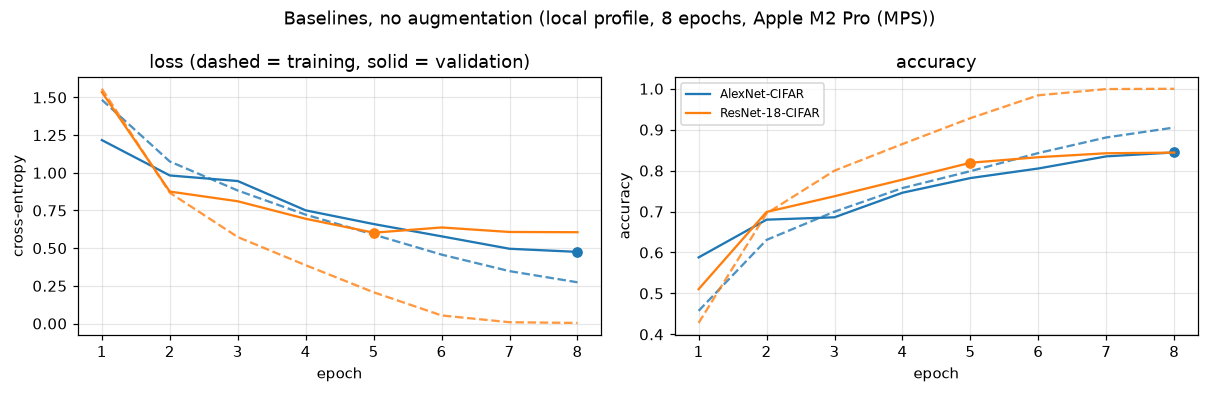

In [18]:
BASELINES = {
    "alexnet": RunConfig("alexnet_base", "alexnet", dropout=0.5),
    "resnet": RunConfig("resnet18_base", "resnet"),
}
RECORDS, MODELS = {}, {}
for key, cfg in BASELINES.items():
    RECORDS[cfg.name], MODELS[cfg.name] = train_run(cfg)

base_records = [RECORDS[c.name] for c in BASELINES.values()]
display(summary(base_records))
plot_curves(base_records, f"Baselines, no augmentation ({PROFILE} profile, {P['epochs']} epochs, {DEVICE_NAME})",
            labels=["AlexNet-CIFAR", "ResNet-18-CIFAR"], fname="t2_baselines")

### 2.7 The role of residual connections
A residual block learns a correction $F(x)$ that is *added* to its input, $y = \mathrm{ReLU}(F(x) + x)$, instead of a full mapping $y = \mathrm{ReLU}(F(x))$. Two consequences:
1. **Easy identity.** If a block is not useful, it only has to drive $F$ towards zero, rather than learning an exact identity through two convolutions and ReLUs. Adding layers therefore should not make the network harder to optimize ("degradation problem", He et al. 2016).
2. **Gradient path.** $\partial y / \partial x = I + \partial F / \partial x$: the identity term carries the gradient from the loss straight back to early layers, so it is not only the product of many layer Jacobians.

To isolate the effect we train a **plain-18** network: exactly the same convolutions, BatchNorm, widths, optimizer and budget as ResNet-18, but with all shortcuts removed (it has 0.16 M fewer parameters because the three 1×1 projections are gone). We also measure, at initialization, the gradient norm that reaches each block on one fixed batch.

[loaded] plain18_noskip: val acc 0.8616, best epoch 7


,residual,params (M),MMACs / image,s / epoch,train time (min),best epoch,train acc,val acc,gap (train − val),train CE,val CE,val macro-F1
run,,,,,,,,,,,,
resnet18_base,True,11.1740,555.4227,58.7944,7.8393,5,0.9744,0.8192,0.1552,0.0913,0.6027,0.8194
plain18_noskip,False,11.0001,549.1313,52.5835,7.0111,7,0.9986,0.8616,0.1370,0.0117,0.4987,0.8615


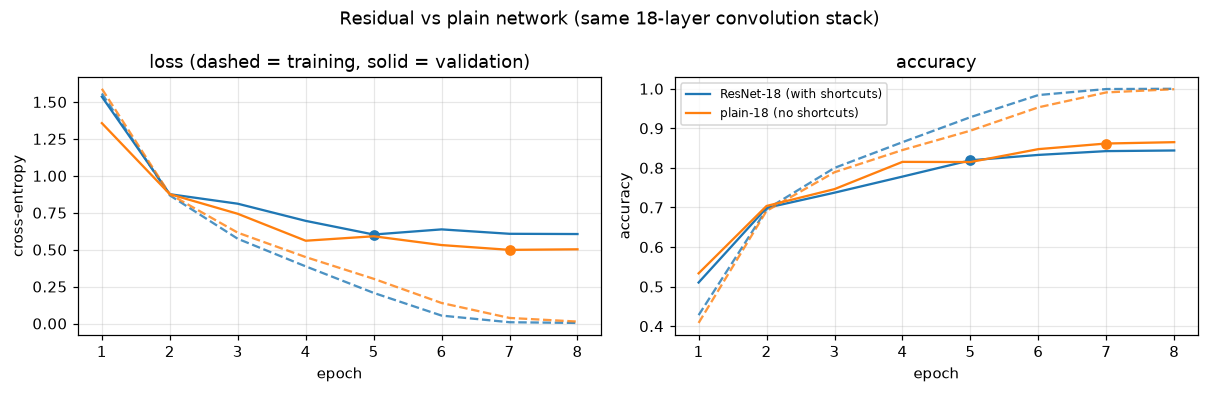

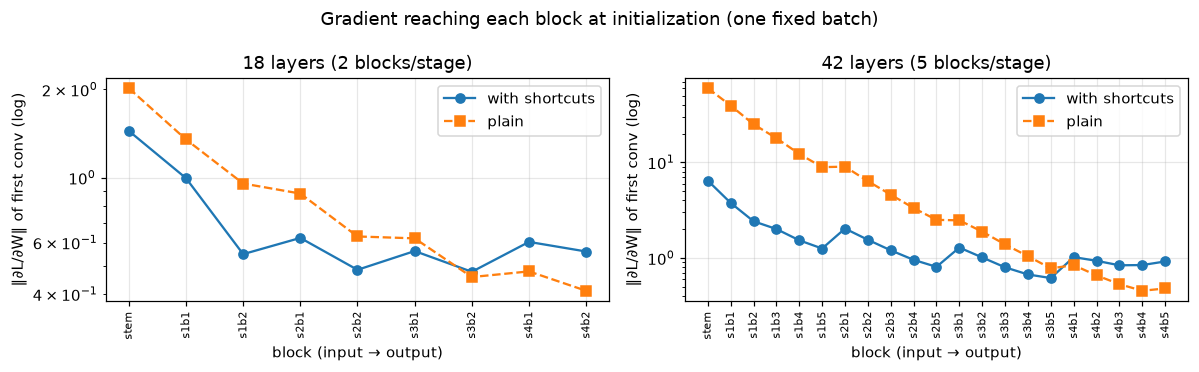

In [19]:
plain_cfg = RunConfig("plain18_noskip", "resnet", residual=False)
RECORDS[plain_cfg.name], MODELS[plain_cfg.name] = train_run(plain_cfg)

skip_records = [RECORDS["resnet18_base"], RECORDS[plain_cfg.name]]
display(summary(skip_records, extra=("residual",)))
plot_curves(skip_records, "Residual vs plain network (same 18-layer convolution stack)",
            labels=["ResNet-18 (with shortcuts)", "plain-18 (no shortcuts)"], fname="t2_residual_vs_plain")


def init_gradient_norms(residual, blocks=(2, 2, 2, 2), seed=BASE_SEED):
    # Gradient norm of the first conv weight of every block, at initialization, for one fixed batch.
    set_seed(seed)
    model = ResNetCIFAR(blocks=blocks, residual=residual).to(device).train()
    xb, yb, _ = next(iterate(SPLITS["train"], 256))
    F.cross_entropy(model(to_float(xb)), yb).backward()
    names, norms = ["stem"], [model.stem[0].weight.grad.norm().item()]
    for i, stage in enumerate(model.stages):
        for j, block in enumerate(stage):
            names.append(f"s{i + 1}b{j + 1}")
            norms.append(block.conv1.weight.grad.norm().item())
    return names, norms


fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, blocks, title in zip(axes, [(2, 2, 2, 2), (5, 5, 5, 5)], ["18 layers (2 blocks/stage)", "42 layers (5 blocks/stage)"]):
    for residual, style in [(True, "o-"), (False, "s--")]:
        names, norms = init_gradient_norms(residual, blocks)
        ax.semilogy(range(len(names)), norms, style, label="with shortcuts" if residual else "plain")
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=90, fontsize=7)
    ax.set(title=title, xlabel="block (input → output)", ylabel="‖∂L/∂W‖ of first conv (log)")
    ax.legend()
fig.suptitle("Gradient reaching each block at initialization (one fixed batch)")
fig.tight_layout()
savefig(fig, "t2_init_gradients")
plt.show()

**Does the advantage of shortcuts grow with depth?** At 18 layers BatchNorm alone keeps the plain network trainable, so we repeat the comparison at **42 layers** (5 blocks per stage). To keep this affordable both depths use the width-0.25 network (16–128 channels); everything else is the 2.5 procedure. The 18-layer residual run is shared with Task 3.1. This is an experimental variant, not a baseline.

[loaded] resnet18_w0.25: val acc 0.8080, best epoch 6


           plain18_w0.25 | epoch  1/8 | train CE 1.778 acc 0.329 | val CE 1.546 acc 0.443 |  14.7 s


           plain18_w0.25 | epoch  2/8 | train CE 1.108 acc 0.600 | val CE 1.399 acc 0.542 |  16.0 s


           plain18_w0.25 | epoch  3/8 | train CE 0.825 acc 0.709 | val CE 0.902 acc 0.692 |  16.8 s


           plain18_w0.25 | epoch  4/8 | train CE 0.662 acc 0.768 | val CE 0.729 acc 0.751 |  13.7 s


           plain18_w0.25 | epoch  5/8 | train CE 0.532 acc 0.814 | val CE 0.690 acc 0.771 |  13.6 s


... (16 outputs left out)

           plain42_w0.25 | epoch  6/8 | train CE 0.866 acc 0.693 | val CE 0.932 acc 0.671 |  30.0 s


           plain42_w0.25 | epoch  7/8 | train CE 0.737 acc 0.739 | val CE 0.832 acc 0.710 |  28.5 s


           plain42_w0.25 | epoch  8/8 | train CE 0.638 acc 0.777 | val CE 0.824 acc 0.714 |  28.0 s


,blocks,residual,params (M),MMACs / image,s / epoch,train time (min),best epoch,train acc,val acc,gap (train − val),train CE,val CE,val macro-F1
run,,,,,,,,,,,,,
resnet18_w0.25,"(2, 2, 2, 2)",True,0.7015,35.0467,20.9589,2.7945,6,0.9478,0.8080,0.1398,0.1629,0.6101,0.8083
plain18_w0.25,"(2, 2, 2, 2)",False,0.6903,34.6534,14.5603,1.9414,7,0.9510,0.8096,0.1414,0.1697,0.5726,0.8099
resnet42_w0.25,"(5, 5, 5, 5)",True,1.8794,91.6698,31.9922,4.2656,6,0.9430,0.7988,0.1442,0.1771,0.6431,0.7977
plain42_w0.25,"(5, 5, 5, 5)",False,1.8682,91.2765,28.3221,3.7763,8,0.7950,0.7140,0.0810,0.5881,0.8243,0.7152


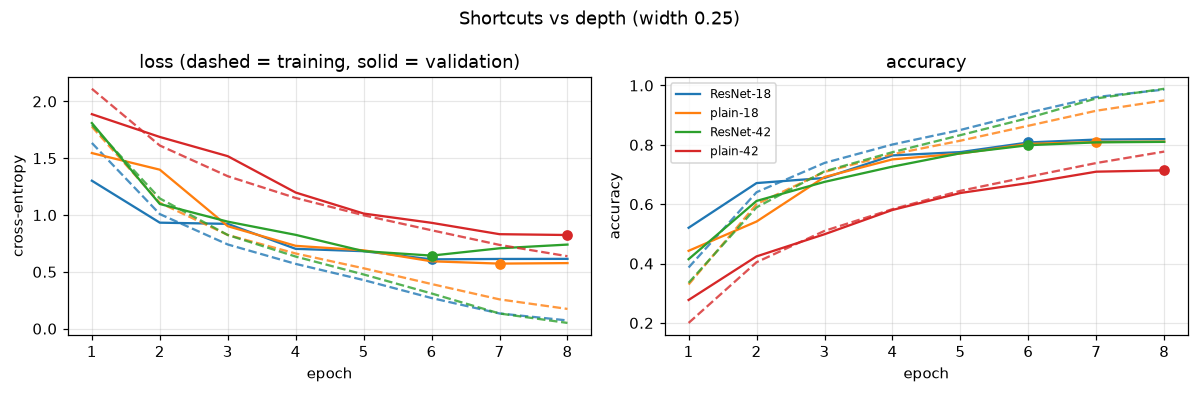

In [20]:
DEPTH_SKIP = [
    RunConfig("resnet18_w0.25", "resnet", width=0.25),
    RunConfig("plain18_w0.25", "resnet", width=0.25, residual=False),
    RunConfig("resnet42_w0.25", "resnet", width=0.25, blocks=(5, 5, 5, 5)),
    RunConfig("plain42_w0.25", "resnet", width=0.25, blocks=(5, 5, 5, 5), residual=False),
]
for cfg in DEPTH_SKIP:
    if cfg.name not in RECORDS:
        RECORDS[cfg.name], MODELS[cfg.name] = train_run(cfg)

recs = [RECORDS[c.name] for c in DEPTH_SKIP]
display(summary(recs, extra=("blocks", "residual")))
plot_curves(recs, "Shortcuts vs depth (width 0.25)",
            labels=["ResNet-18", "plain-18", "ResNet-42", "plain-42"], fname="t2_depth_vs_skip")


### 2.8 Baseline comparison

All numbers: `local` profile, 8 epochs, Apple M4 (MPS), FP32, seed 42, no augmentation; accuracy and cross-entropy of the selected checkpoint (lowest validation CE), evaluated in eval mode. *Final-epoch* validation accuracy is quoted where it differs from the selected checkpoint.

| | AlexNet-CIFAR | ResNet-18-CIFAR |
|---|---|---|
| Parameters | 7.71 M (5.3 M = 68 % in the FC head) | 11.17 M (5 k in the head) |
| MACs per image | 226 M | 555 M (2.5×) |
| Training time per epoch (M4) | 23.7 s | 58.8 s (2.5×) |
| Selected epoch | 8 | 5 |
| Train / validation accuracy | 92.1 % / **84.4 %** | 97.4 % / 81.9 % (final epoch: 84.4 %) |
| Validation cross-entropy | **0.475** | 0.603 |

**Under this budget AlexNet-CIFAR is the better baseline.** It reaches the same final-epoch validation accuracy as ResNet-18 (84.4 %) and a clearly lower validation loss, at 40 % of the compute. The curves show why. ResNet-18 has no dropout and gets no augmentation, so it fits the training set almost perfectly (running training accuracy 98 % at epoch 6 and 100 % at epoch 7). After epoch 5 its validation CE rises again (0.60 → 0.64 → 0.61) even though validation accuracy keeps increasing. The model becomes over-confident on the images it gets wrong. Checkpoint selection by CE therefore picks epoch 5. AlexNet's dropout (p = 0.5) keeps its training accuracy at 92 %, the train–validation gap is half as large (7.6 vs 15.5 points), and its validation CE is still falling at epoch 8. This shows that **without augmentation the comparison is about regularization, not about representational power**. ResNet-18 is expected to benefit much more from augmentation and from longer training (Task 4). One seed per model, so differences of about 1 point are within run-to-run noise (Task 6 repeats seeds).

**Choosing by CE or by accuracy matters.** For ResNet-18 the two rules disagree by 2.5 points of accuracy. We keep the CE rule (decided before seeing results, as in Lab 1) because it favours calibrated models. We report the difference here instead of switching rules after seeing the data.

**Residual connections.**
* At **18 layers** the shortcuts do *not* help here. Plain-18 trains just as fast (training CE 0.01 at its selected epoch 7) and reaches a higher validation accuracy (86.2 % vs 81.9 %; final epoch 86.5 % vs 84.4 %). It is also 10 % faster per epoch (52.6 s vs 58.8 s), because it has no projection convolutions and no additions. With BatchNorm and a good initialization, an 18-layer plain network has no optimization problem, so the shortcuts bring no benefit at this depth. The accuracy advantage of plain-18 is a single-seed result and should not be over-interpreted.
* At **42 layers** (width 0.25) the plain network clearly fails to optimize. Its selected checkpoint still has training accuracy 79.5 % and training CE 0.59, versus 95.1 % and 0.17 for plain-18. Its validation accuracy drops from 81.0 % to 71.4 %. **The deeper plain network fits the training data worse than the shallower one, which is the degradation problem of He et al.** ResNet-42 trains as easily as ResNet-18 (running training CE 0.05 in the last epoch; validation 79.9 % vs 80.8 %). Adding depth with shortcuts is therefore harmless to optimization. In this short, unaugmented budget it does not improve accuracy, but it does not break training either.
* The gradient measurement at initialization shows the mechanism. In plain-42 the gradient norm grows by more than 100× from the output block to the stem, while in ResNet-42 it varies by only about 10× and partly resets at each stage. Through many stacked BN–ReLU–conv layers the gradient scale compounds layer by layer (here it explodes towards the input). The identity term $I + \partial F/\partial x$ in each residual block keeps the back-propagated signal close to its original scale, so all layers learn at a similar rate.

# Task 3. Capacity and regularization

All runs in this section use the training procedure of 2.5 (same data, no augmentation, optimizer, schedule, epochs and seed); each comparison changes **one** factor, and the baseline of Task 2 is reused as one of its points. Results are reported on the validation split; the test split is still unused.

| Comparison | Model | Changed | Held fixed |
|---|---|---|---|
| 3.1 Width | ResNet-18 | channel multiplier 0.25 / 0.5 / **1.0** (16–128 … 64–512 channels) | depth (2-2-2-2 blocks), WD 5·10⁻⁴, no dropout |
| 3.2 Depth | ResNet, width 1.0 | blocks per stage 1 / **2** / 3 (ResNet-10 / **18** / 26) | width, WD, no dropout |
| 3.3 L2 | AlexNet-CIFAR | weight decay 0 / 5·10⁻⁴ / 5·10⁻³ | width 1.0, **dropout 0** (to isolate L2) |
| 3.4 Dropout | AlexNet-CIFAR | dropout in the FC head 0 / **0.5** / 0.75 | width 1.0, WD 5·10⁻⁴ |

Bold = the Task 2 baseline. Capacity is studied on ResNet (where width and depth are well-defined, and where the residual connections make deeper variants trainable); regularization on AlexNet, which has a large FC head where dropout is applied in the original architecture and which overfits most without augmentation. The AlexNet run with WD 5·10⁻⁴ and dropout 0 is shared by 3.3 and 3.4.

In [21]:
T3 = {
    "width": [RunConfig("resnet18_w0.25", "resnet", width=0.25), RunConfig("resnet18_w0.5", "resnet", width=0.5), BASELINES["resnet"]],
    "depth": [RunConfig("resnet10", "resnet", blocks=(1, 1, 1, 1)), BASELINES["resnet"], RunConfig("resnet26", "resnet", blocks=(3, 3, 3, 3))],
    "l2": [RunConfig("alexnet_wd0_do0", "alexnet", dropout=0.0, weight_decay=0.0),
           RunConfig("alexnet_wd5e-4_do0", "alexnet", dropout=0.0, weight_decay=5e-4),
           RunConfig("alexnet_wd5e-3_do0", "alexnet", dropout=0.0, weight_decay=5e-3)],
}
T3["dropout"] = [T3["l2"][1], BASELINES["alexnet"], RunConfig("alexnet_wd5e-4_do0.75", "alexnet", dropout=0.75)]

for group in T3.values():
    for cfg in group:
        if cfg.name not in RECORDS:
            RECORDS[cfg.name], MODELS[cfg.name] = train_run(cfg)

[loaded] resnet18_w0.5: val acc 0.8280, best epoch 7


[loaded] resnet10: val acc 0.8258, best epoch 7


[loaded] resnet26: val acc 0.8142, best epoch 5
[loaded] alexnet_wd0_do0: val acc 0.8580, best epoch 7


[loaded] alexnet_wd5e-4_do0: val acc 0.8578, best epoch 7
[loaded] alexnet_wd5e-3_do0: val acc 0.8626, best epoch 8


[loaded] alexnet_wd5e-4_do0.75: val acc 0.8270, best epoch 8


### 3.1 Width

,width,params (M),MMACs / image,s / epoch,train time (min),best epoch,train acc,val acc,gap (train − val),train CE,val CE,val macro-F1
run,,,,,,,,,,,,
resnet18_w0.25,0.25,0.7015,35.0467,20.9589,2.7945,6,0.9478,0.8080,0.1398,0.1629,0.6101,0.8083
resnet18_w0.5,0.50,2.7976,139.2993,22.3294,2.9772,7,0.9998,0.8280,0.1718,0.0083,0.6162,0.8283
resnet18_base,1.00,11.1740,555.4227,58.7944,7.8393,5,0.9744,0.8192,0.1552,0.0913,0.6027,0.8194


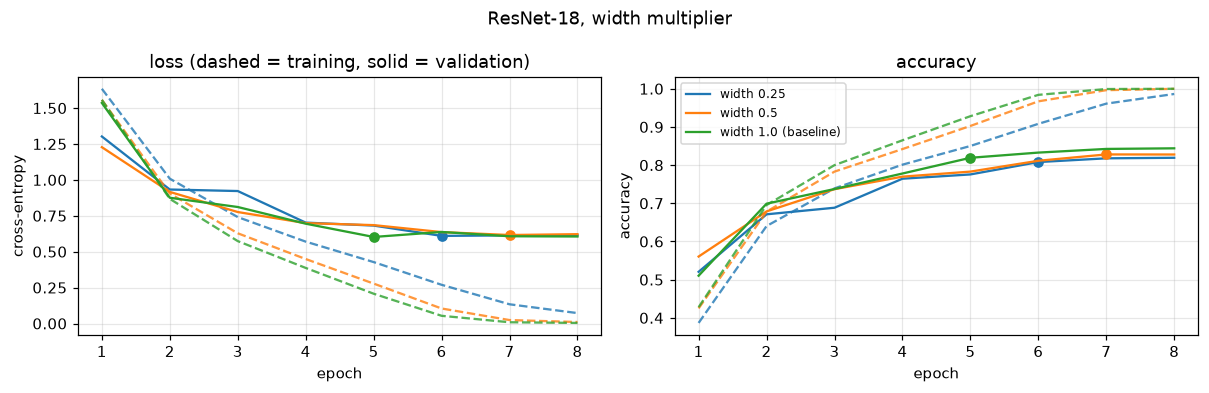

In [22]:
recs = [RECORDS[c.name] for c in T3["width"]]
display(summary(recs, extra=("width",)))
plot_curves(recs, "ResNet-18, width multiplier", labels=["width 0.25", "width 0.5", "width 1.0 (baseline)"], fname="t3_width")

### 3.2 Depth

,blocks,params (M),MMACs / image,s / epoch,train time (min),best epoch,train acc,val acc,gap (train − val),train CE,val CE,val macro-F1
run,,,,,,,,,,,,
resnet10,"(1, 1, 1, 1)",4.9032,253.4328,34.8191,4.6425,7,0.9996,0.8258,0.1738,0.0134,0.5787,0.8263
resnet18_base,"(2, 2, 2, 2)",11.1740,555.4227,58.7944,7.8393,5,0.9744,0.8192,0.1552,0.0913,0.6027,0.8194
resnet26,"(3, 3, 3, 3)",17.4447,857.4126,80.7349,10.7646,5,0.9566,0.8142,0.1424,0.1376,0.5989,0.8177


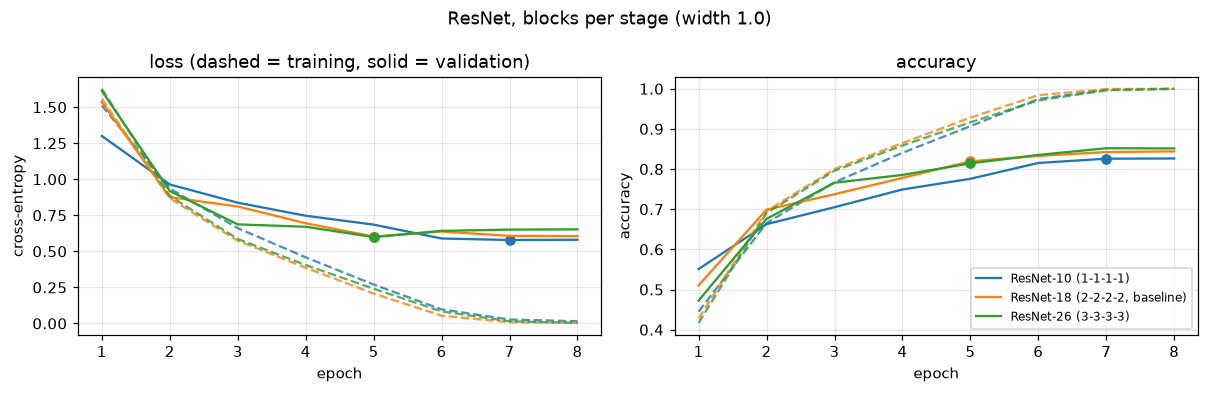

In [23]:
recs = [RECORDS[c.name] for c in T3["depth"]]
display(summary(recs, extra=("blocks",)))
plot_curves(recs, "ResNet, blocks per stage (width 1.0)", labels=["ResNet-10 (1-1-1-1)", "ResNet-18 (2-2-2-2, baseline)", "ResNet-26 (3-3-3-3)"], fname="t3_depth")

### 3.3 L2 regularization (weight decay)
With SGD, adding $\frac{\lambda}{2}\lVert w\rVert^2$ to the loss is the same as the `weight_decay=λ` update $w \leftarrow w - \eta(\nabla L + \lambda w)$. It is applied to conv and linear weights only. Note that for layers followed by BatchNorm the scale of the weights does not change the function, so there weight decay mainly increases the *effective* learning rate; it acts as a classic penalty on the FC layers.

,weight_decay,dropout,params (M),MMACs / image,s / epoch,train time (min),best epoch,train acc,val acc,gap (train − val),train CE,val CE,val macro-F1
run,,,,,,,,,,,,,
alexnet_wd0_do0,0.0000,0.0,7.7076,225.6507,23.2509,3.1001,7,0.9758,0.8580,0.1178,0.0816,0.5177,0.8577
alexnet_wd5e-4_do0,0.0005,0.0,7.7076,225.6507,23.4731,3.1297,7,0.9726,0.8578,0.1148,0.0891,0.4764,0.8576
alexnet_wd5e-3_do0,0.0050,0.0,7.7076,225.6507,23.6065,3.1475,8,0.9594,0.8626,0.0968,0.1430,0.4082,0.8629


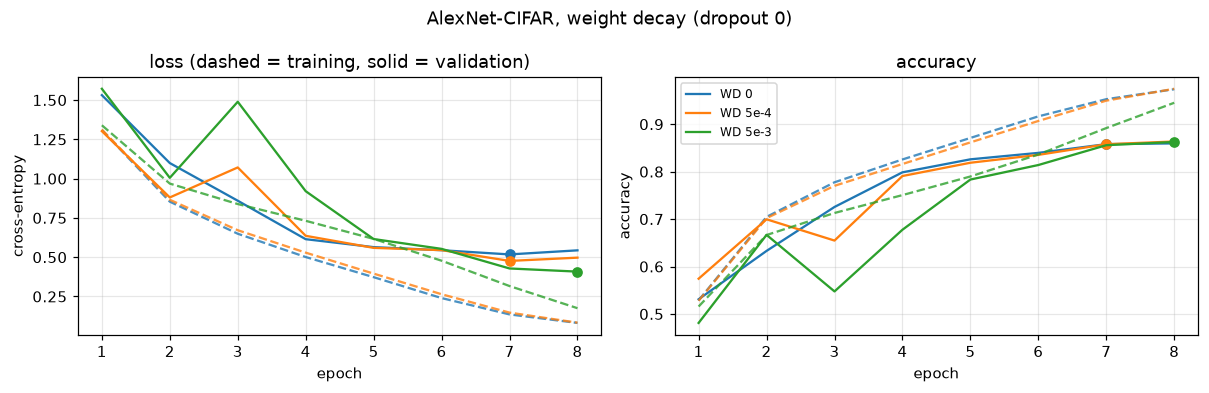

,alexnet_wd0_do0,alexnet_wd5e-4_do0,alexnet_wd5e-3_do0
‖W‖ of the selected checkpoint,,,
features.0.0,10.22,8.35,3.55
features.2.0,13.67,10.99,4.47
features.4.0,15.37,11.93,4.25
features.5.0,13.49,10.63,3.97
features.6.0,12.98,10.21,3.78
classifier.2,22.07,16.39,4.20
classifier.5,19.74,14.19,2.58
classifier.7,4.66,3.93,2.37


In [24]:
recs = [RECORDS[c.name] for c in T3["l2"]]
display(summary(recs, extra=("weight_decay", "dropout")))
plot_curves(recs, "AlexNet-CIFAR, weight decay (dropout 0)", labels=["WD 0", "WD 5e-4", "WD 5e-3"], fname="t3_l2")


def weight_norms(model):
    return {n: p.norm().item() for n, p in model.named_parameters() if p.ndim > 1}


norms = pd.DataFrame({c.name: weight_norms(MODELS[c.name]) for c in T3["l2"]})
norms.index = [n.replace(".weight", "") for n in norms.index]
display(norms.round(2).rename_axis("‖W‖ of the selected checkpoint"))

### 3.4 Dropout
Dropout zeroes each input of the two hidden FC layers with probability p during training (and rescales the rest by 1/(1−p)); at evaluation it is switched off. It prevents co-adaptation of hidden units and acts like an average over many thinned networks. The running training accuracy in the curves is measured *with* dropout on, so it underestimates the actual training accuracy; the table uses the deterministic `train_eval` evaluation.

,weight_decay,dropout,params (M),MMACs / image,s / epoch,train time (min),best epoch,train acc,val acc,gap (train − val),train CE,val CE,val macro-F1
run,,,,,,,,,,,,,
alexnet_wd5e-4_do0,0.0005,0.00,7.7076,225.6507,23.4731,3.1297,7,0.9726,0.8578,0.1148,0.0891,0.4764,0.8576
alexnet_base,0.0005,0.50,7.7076,225.6507,23.6910,3.1588,8,0.9208,0.8444,0.0764,0.2248,0.4754,0.8441
alexnet_wd5e-4_do0.75,0.0005,0.75,7.7076,225.6507,23.3127,3.1084,8,0.8756,0.8270,0.0486,0.3809,0.5220,0.8280


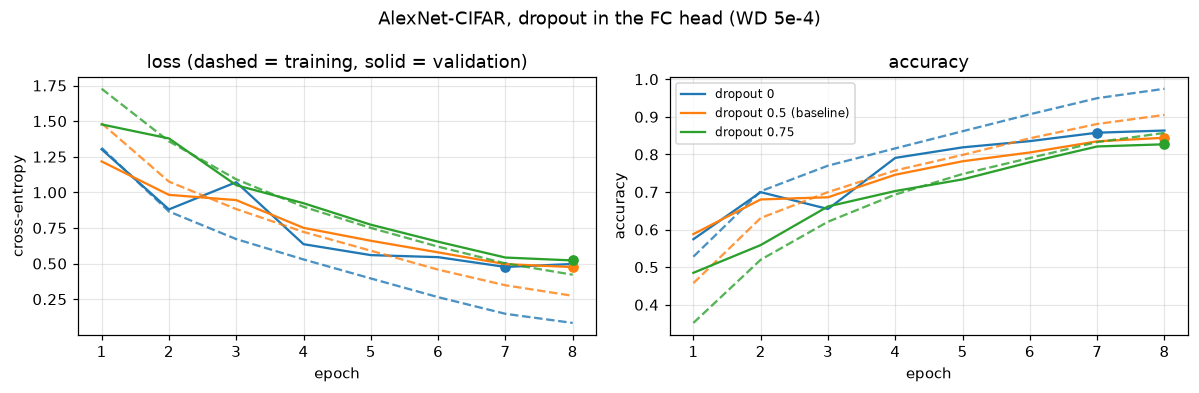

In [25]:
recs = [RECORDS[c.name] for c in T3["dropout"]]
display(summary(recs, extra=("weight_decay", "dropout")))
plot_curves(recs, "AlexNet-CIFAR, dropout in the FC head (WD 5e-4)", labels=["dropout 0", "dropout 0.5 (baseline)", "dropout 0.75"], fname="t3_dropout")

,params (M),MMACs / image,s / epoch,train time (min),best epoch,train acc,val acc,gap (train − val),train CE,val CE,val macro-F1
run,,,,,,,,,,,
alexnet_base,7.7076,225.6507,23.6910,3.1588,8,0.9208,0.8444,0.0764,0.2248,0.4754,0.8441
resnet18_base,11.1740,555.4227,58.7944,7.8393,5,0.9744,0.8192,0.1552,0.0913,0.6027,0.8194
plain18_noskip,11.0001,549.1313,52.5835,7.0111,7,0.9986,0.8616,0.1370,0.0117,0.4987,0.8615
resnet18_w0.25,0.7015,35.0467,20.9589,2.7945,6,0.9478,0.8080,0.1398,0.1629,0.6101,0.8083
resnet18_w0.5,2.7976,139.2993,22.3294,2.9772,7,0.9998,0.8280,0.1718,0.0083,0.6162,0.8283
resnet10,4.9032,253.4328,34.8191,4.6425,7,0.9996,0.8258,0.1738,0.0134,0.5787,0.8263
resnet26,17.4447,857.4126,80.7349,10.7646,5,0.9566,0.8142,0.1424,0.1376,0.5989,0.8177
alexnet_wd0_do0,7.7076,225.6507,23.2509,3.1001,7,0.9758,0.8580,0.1178,0.0816,0.5177,0.8577
alexnet_wd5e-4_do0,7.7076,225.6507,23.4731,3.1297,7,0.9726,0.8578,0.1148,0.0891,0.4764,0.8576


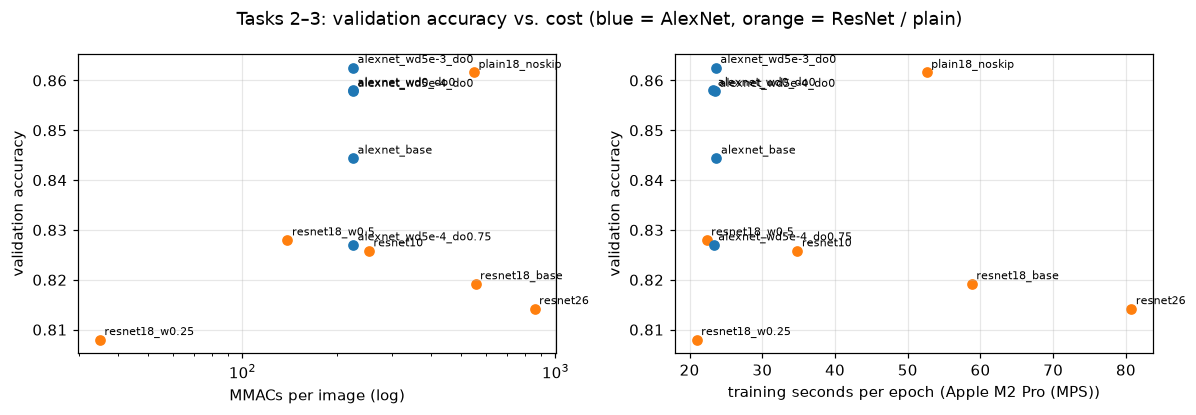

In [26]:
# Overview of all Task 2-3 runs (accuracy vs. cost)
all_recs = [RECORDS[n] for n in dict.fromkeys(c.name for g in [list(BASELINES.values()), [plain_cfg]] + list(T3.values()) for c in g)]
overview = summary(all_recs)
display(overview)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, xcol, xlabel in [(axes[0], "MMACs / image", "MMACs per image (log)"), (axes[1], "s / epoch", f"training seconds per epoch ({DEVICE_NAME})")]:
    for name, row in overview.iterrows():
        ax.scatter(row[xcol], row["val acc"], color="C0" if name.startswith("alexnet") else "C1")
        ax.annotate(name, (row[xcol], row["val acc"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set(xlabel=xlabel, ylabel="validation accuracy")
axes[0].set_xscale("log")
fig.suptitle("Tasks 2–3: validation accuracy vs. cost (blue = AlexNet, orange = ResNet / plain)")
fig.tight_layout()
savefig(fig, "t3_cost_overview")
plt.show()

### 3.5 Discussion

All runs: same procedure and budget as 2.5 (8 epochs, no augmentation, seed 42, M4/MPS), one factor changed per comparison. Accuracies refer to the selected checkpoint unless *final epoch* is stated.

**3.1 Width (ResNet-18; depth, WD 5·10⁻⁴, no dropout held fixed).**

| width | params | MMACs | s/epoch | train acc | val acc | val acc, final epoch | val CE |
|---|---|---|---|---|---|---|---|
| 0.25 | 0.70 M | 35 | 21.0 | 94.8 % | 80.8 % | 81.9 % | 0.610 |
| 0.5 | 2.80 M | 139 | 22.3 | 100.0 % | 82.8 % | 82.8 % | 0.616 |
| 1.0 | 11.17 M | 555 | 58.8 | 97.4 % | 81.9 % | 84.4 % | 0.603 |

None of the widths underfits: all reach 96–100 % running training accuracy by the last epoch. A 16× increase in parameters and MACs buys about 2.5 points of final-epoch validation accuracy and no improvement in validation CE. The gap between training and validation grows with width, so **the limit is overfitting, not capacity**. Cost does not scale with MACs on the M4. Widths 0.25 and 0.5 take almost the same time (21–22 s/epoch) because such small layers do not keep the GPU busy, and per-batch overhead dominates. Only width 1.0 is compute-bound (2.8× slower for 4× more MACs). Width 0.5 is the most efficient point: it is as accurate as width 1.0 at the selected checkpoint, with 4× fewer parameters and 2.6× less training time.

**3.2 Depth (ResNet, width 1.0; WD, no dropout held fixed).**

| model | params | MMACs | s/epoch | train acc | val acc | val acc, final epoch | val CE |
|---|---|---|---|---|---|---|---|
| ResNet-10 (1-1-1-1) | 4.90 M | 253 | 34.8 | 100.0 % | 82.6 % | 82.6 % | 0.579 |
| ResNet-18 (2-2-2-2) | 11.17 M | 555 | 58.8 | 97.4 % | 81.9 % | 84.4 % | 0.603 |
| ResNet-26 (3-3-3-3) | 17.44 M | 857 | 80.7 | 95.7 % | 81.4 % | 85.1 % | 0.599 |

Deeper residual networks optimize without difficulty (all reach 100 % running training accuracy), and final-epoch accuracy rises slightly with depth (82.6 → 84.4 → 85.1 %). Validation CE, however, does not improve, and the two deeper models reach their CE minimum at epoch 5 and then become over-confident. Training time grows close to linearly with depth (35 → 59 → 81 s/epoch). Without augmentation, neither more depth nor more width is worth its cost under this budget. ResNet-10 has the best validation CE at 0.6× the time of ResNet-18.

**3.3 L2 regularization (AlexNet-CIFAR, dropout 0).**

| weight decay | train acc | val acc | gap | train CE | val CE | ‖W_fc6‖ |
|---|---|---|---|---|---|---|
| 0 | 97.6 % | 85.8 % | 11.8 | 0.082 | 0.518 | 22.1 |
| 5·10⁻⁴ | 97.3 % | 85.8 % | 11.5 | 0.089 | 0.476 | 16.4 |
| 5·10⁻³ | 95.9 % | **86.3 %** | **9.7** | 0.143 | **0.408** | 4.2 |

Weight decay works as expected. It shrinks the weights (the FC6 norm drops by 5× at 5·10⁻³), raises the training loss, narrows the generalization gap, and gives the lowest validation CE of all AlexNet runs (0.408 vs 0.518 without decay). Accuracy barely changes (+0.5 points), so most of the benefit is in calibration: the unregularized model is over-confident. Strong decay makes the early epochs unstable (validation CE spikes to 1.49 at epoch 3 at the peak learning rate). For the BN-normalized conv layers, weight decay mainly raises the effective learning rate, which explains the noise. The run recovers once the learning rate decays. L2 costs nothing extra per epoch (23.3–23.6 s).

**3.4 Dropout (AlexNet-CIFAR, WD 5·10⁻⁴).**

| dropout | train acc | val acc | gap | train CE | val CE | selected epoch |
|---|---|---|---|---|---|---|
| 0 | 97.3 % | **85.8 %** | 11.5 | 0.089 | 0.476 | 7 |
| 0.5 (baseline) | 92.1 % | 84.4 % | 7.6 | 0.225 | **0.475** | 8 |
| 0.75 | 87.6 % | 82.7 % | 4.9 | 0.381 | 0.522 | 8 |

Dropout reduces overfitting monotonically: the gap shrinks from 11.5 to 7.6 to 4.9 points. Within 8 epochs, however, it also **slows fitting**. With p = 0.75 the training CE is still 0.38, and both training and validation loss are still falling at the last epoch, which is underfitting caused by the budget. Validation accuracy therefore drops (85.8 → 84.4 → 82.7 %). p = 0.5 matches the validation CE of no dropout with a smaller gap, so it is better calibrated but not more accurate in this budget. Dropout has no effect on cost per epoch or at inference, but it needs more epochs to converge. It would likely pay off in a longer run, where the unregularized model keeps overfitting. In this budget, L2 (5·10⁻³) is the more effective regularizer for AlexNet.

**Summary.** Under an 8-epoch, unaugmented budget, every model in Tasks 2–3 that can fit the data does so, and the train–validation gap (10–17 points) is the main limitation. More capacity (width or depth) increases cost roughly in proportion to MACs on a busy GPU, but adds at most a few points of final-epoch accuracy and does not improve validation CE. Explicit regularization (L2, dropout) narrows the gap at no per-epoch cost, with L2 improving validation CE the most. These conclusions depend on the short training and on the lack of augmentation, which Task 4 adds. They are single-seed results and should be confirmed with repeated seeds (Task 6). The test split has still not been used.
